# Fig. 2c-d: Parameter space vs. fitted parameters

[AI generated summary] Performance (probability of choosing the high-payoff target) of simulated agents across their parameter space, with the parameters fitted to the monkeys:
- **Fig. 2c**: inferential RL model (without stickiness) as a function of the learning rate (dots: learning rates of this model fitted to the monkeys).
- **Fig. 2d**: foraging model as a function of learning rate and switch threshold (dots: mean of the bootstrapped fits).

**How to run:** run all cells. The grid search simulates the agents and takes a few minutes. Figures are saved in `figs/`.

**Results:** precomputed results are provided in `results/behav_modeling/fitting and results/behav_modeling/bootstrap` (see the README). To recompute them, run in this folder: `python run_model_fitting.py` (Fig. 2c dots) and `python run_bootstrapping.py` (Fig. 2d dots; 100 bootstrap fits per model and monkey, many hours).

Source data of the plotted panels are exported to `source_data/` (see `popy/source_data.py`).

---
# Setup

In [1]:
# imports
import os
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from popy.config import COLORS
import popy.config as cfg
from helpers import grid_search_RL, grid_search_foraging, load_fitting_results

from popy.config import RESULTS_PATH
results_dir = os.path.join(RESULTS_PATH, "behav_modeling", "bootstrap")

In [2]:
import os
from popy.config import FIGS_PATH
os.makedirs(FIGS_PATH, exist_ok=True)  # the figure panels are saved here

In [3]:
def plot_parameter_grid_RL(alpha_range, res_grid_qlearn_inferential, fitted_params):

    # Set font sizes
    plt.rcParams.update({'font.size': 8})

    # Create a larger figure to accommodate the axis labels and colorbar
    fig, ax = plt.subplots(1, 1, figsize=(4/2.54, 4/2.54))  # Slightly larger to fit everything

    # smooth line plot of the results
    ax.plot(alpha_range, res_grid_qlearn_inferential, color='black')

    # Add parameter points with compact styling (fitted inferential RL without stickiness, i.e. the model of the grid search)
    ka_params = fitted_params['ka']
    po_params = fitted_params['po']

    # plot lines for each parameter set
    ax.axvline(ka_params['alpha'], color=COLORS['ka'])
    ax.axvline(po_params['alpha'], color=COLORS['po'])

    # mark the points
    ax.scatter(ka_params['alpha'],
            np.interp(ka_params['alpha'], alpha_range, res_grid_qlearn_inferential),
            color=COLORS['ka'], s=60, zorder=5, linewidths=1, edgecolors='white', label='KA')
    ax.scatter(po_params['alpha'],
            np.interp(po_params['alpha'], alpha_range, res_grid_qlearn_inferential),
            color=COLORS['po'], s=60, zorder=5, linewidths=1, edgecolors='white', label='PO')

    ax.set_xlabel('Learning Rate (α)')
    ax.set_ylabel('Prob. optimal target')

    ax.set_xlim(0, .5)

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    # Add compact legend
    ax.legend(frameon=True, loc='upper right', fontsize=6, markerscale=0.8)

    return fig, ax

In [4]:
def plot_parameter_grid_foraging(alpha_range, V0_range, res_grid, parameter_summary_df=None):

    # Set font sizes
    plt.rcParams.update({'font.size': 8})

    # Create a larger figure to accommodate the axis labels and colorbar
    fig, ax = plt.subplots(1, 1, figsize=(6/2.54, 6/2.54))  # Slightly larger to fit everything

    # Create nice colormap for the heatmap
    cmap = plt.cm.cividis

    # 
    im = ax.imshow(res_grid, origin='lower', 
                extent=[V0_range[0], V0_range[-1], alpha_range[0], alpha_range[-1]], 
                aspect='equal', interpolation='Gaussian', cmap=cmap)
    # Add colorbar with compact size
    cbar = fig.colorbar(im, ax=ax, fraction=0.04, pad=0.1)
    cbar.set_label('prob. optimal target', fontsize=8)

    # Add contour lines at every 0.1 increment with minimal labels
    levels = np.arange(0, 1, .1)
    contour = ax.contour(
        np.linspace(V0_range[0], V0_range[-1], res_grid.shape[1]),
        np.linspace(alpha_range[0], alpha_range[-1], res_grid.shape[0]), 
        res_grid, 
        levels=levels, colors='white', linewidths=0.5, alpha=0.7
    )
    # Only label a few contours to avoid clutter
    ax.clabel(contour, inline=True, fontsize=6, fmt='%.1f', levels=levels)

    # Add parameter points with compact styling
    #ka_params = cfg.MODEL_PARAMS['ka']
    #po_params = cfg.MODEL_PARAMS['po']

    for monkey in ['KA', 'PO']:
        v0_mean = parameter_summary_df.loc[(parameter_summary_df['model'] == 'Foraging') & (parameter_summary_df['monkey'] == monkey) & (parameter_summary_df['parameter'] == 'V0'), 'mean'].values[0]
        v0_ci_lower = parameter_summary_df.loc[(parameter_summary_df['model'] == 'Foraging') & (parameter_summary_df['monkey'] == monkey) & (parameter_summary_df['parameter'] == 'V0'), 'ci95_low'].values[0]
        v0_ci_upper = parameter_summary_df.loc[(parameter_summary_df['model'] == 'Foraging') & (parameter_summary_df['monkey'] == monkey) & (parameter_summary_df['parameter'] == 'V0'), 'ci95_high'].values[0]
        alpha_mean = parameter_summary_df.loc[(parameter_summary_df['model'] == 'Foraging') & (parameter_summary_df['monkey'] == monkey) & (parameter_summary_df['parameter'] == 'alpha'), 'mean'].values[0]
        alpha_ci_lower = parameter_summary_df.loc[(parameter_summary_df['model'] == 'Foraging') & (parameter_summary_df['monkey'] == monkey) & (parameter_summary_df['parameter'] == 'alpha'), 'ci95_low'].values[0]
        alpha_ci_upper = parameter_summary_df.loc[(parameter_summary_df['model'] == 'Foraging') & (parameter_summary_df['monkey'] == monkey) & (parameter_summary_df['parameter'] == 'alpha'), 'ci95_high'].values[0]

        # plot mean points
        ax.scatter(v0_mean, alpha_mean, color=COLORS[monkey.lower()], s=50, label=monkey.upper(), 
                edgecolor='white', linewidth=1, zorder=10)

        # plot error bars
        #ax.errorbar(v0_mean, alpha_mean, xerr=[[v0_mean - v0_ci_lower], [v0_ci_upper - v0_mean]], yerr=[[alpha_mean - alpha_ci_lower], [alpha_ci_upper - alpha_mean]],
        #            fmt='none', ecolor=COLORS[monkey.lower()], elinewidth=1, capsize=3, zorder=9)
    
    # Labels
    ax.set_xlabel('Switch threshold (tau)')
    ax.set_ylabel('Learning Rate (α)')

    # Add compact legend
    ax.legend(frameon=True, loc='upper right', fontsize=6, markerscale=0.8)

    return fig, ax

---
# Set up environment

In [5]:
env = gym.make("zsombi/monkey-bandit-task-v0", n_arms=3, max_episode_steps=10_000)

---
# Load fitted parameters

In [6]:
# learning rates of the inferential RL model without stickiness fitted to the monkeys (Fig. 2c)
res_fit = load_fitting_results()
fitted_params_RL = {monkey: {'alpha': res_fit.loc[(res_fit['monkey'] == monkey) & (res_fit['Model'] == 'Inferential RL'), 'alpha'].values[0]}
                    for monkey in ['ka', 'po']}
fitted_params_RL

{'ka': {'alpha': 0.126755865193123}, 'po': {'alpha': 0.1509880099726033}}

In [7]:
# load bootstrap results
# Load results from CSV files for each monkey
monkeys = ["ka", "po"]
results_dfs = {}

for monkey in monkeys:
    csv_path = os.path.join(results_dir, f"{monkey}_bootstrap_all_models.csv")
    if os.path.exists(csv_path):
        results_dfs[monkey] = pd.read_csv(csv_path)
        print(f"Loaded {monkey.upper()}: {len(results_dfs[monkey])} rows")
        print(f"Columns: {results_dfs[monkey].columns.tolist()}\n")
    else:
        print(f"Warning: File not found for {monkey} at {csv_path}")

# Combine results from both monkeys
if results_dfs:
    combined_df = pd.concat(
        [df.assign(monkey=monkey) for monkey, df in results_dfs.items()],
        ignore_index=True
    )
    print(f"Combined data shape: {combined_df.shape}")
    print(f"Models in data: {combined_df['model'].unique()}")
else:
    print("No results files found!")

# Identify parameter columns (exclude metadata columns)
metadata_cols = {"model", "bootstrap_idx", "monkey", "best_ll", "bic", "lpt", "fit_time_sec"}
param_cols = [col for col in combined_df.columns if col not in metadata_cols]

print(f"Parameter columns identified: {param_cols}")

# Build summary DataFrame (mean, std, and percentile-based 95% CI) before plotting
summary_rows = []
for (model, monkey), group in combined_df.groupby(["model", "monkey"]):
    for param in param_cols:
        values = group[param].dropna()
        if values.empty:
            continue
        summary_rows.append(
            {
                "model": model,
                "monkey": monkey.upper(),
                "parameter": param,
                "n": len(values),
                "mean": values.mean(),
                "std": values.std(ddof=1),
                "ci95_low": values.quantile(0.025),
                "ci95_high": values.quantile(0.975),
            }
        )

parameter_summary_df = pd.DataFrame(summary_rows)

parameter_summary_df

Loaded KA: 300 rows
Columns: ['model', 'bootstrap_idx', 'alpha', 'beta', 'V0', 'best_ll', 'bic', 'lpt', 'fit_time_sec', 'stickiness_bias']

Loaded PO: 300 rows
Columns: ['model', 'bootstrap_idx', 'alpha', 'beta', 'V0', 'best_ll', 'bic', 'lpt', 'fit_time_sec', 'stickiness_bias']

Combined data shape: (600, 11)
Models in data: ['Foraging' 'Inferential RL - stickiness' 'Standard RL - stickiness']
Parameter columns identified: ['alpha', 'beta', 'V0', 'stickiness_bias']


,model,monkey,parameter,n,mean,std,ci95_low,ci95_high
0,Foraging,KA,alpha,100,0.409309,0.014155,0.384186,0.438126
1,Foraging,KA,beta,100,10.784697,0.449931,10.074108,11.703714
2,Foraging,KA,V0,100,0.119132,0.011374,0.102036,0.141229
3,Foraging,PO,alpha,100,0.296873,0.014563,0.269918,0.323805
4,Foraging,PO,beta,100,7.046401,0.359498,6.408560,7.715141
5,Foraging,PO,V0,100,0.183397,0.026320,0.136953,0.236646
6,Inferential RL - stickiness,KA,alpha,100,0.322333,0.047502,0.263570,0.430927
7,Inferential RL - stickiness,KA,beta,100,4.635358,0.360014,3.953430,5.297724
8,Inferential RL - stickiness,KA,stickiness_bias,100,3.092893,0.186747,2.763178,3.449025
9,Inferential RL - stickiness,PO,alpha,100,0.471732,0.135289,0.266386,0.780337


---
# Create figures
## Fig. 2c-d, Parameter space vs fitted model parameters

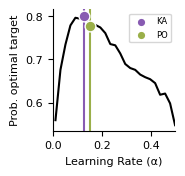

In [8]:
alpha_range, res_grid_qlearn_inferential = grid_search_RL(env, n_samples=25)
fig, ax = plot_parameter_grid_RL(alpha_range, res_grid_qlearn_inferential, fitted_params_RL)
fig.savefig(os.path.join(FIGS_PATH, 'fig2c_parameter_space_RL.svg'), dpi=300, bbox_inches='tight', transparent=True)
plt.show()

In [9]:
# Export source data (Figure 2c)
from popy.source_data import export_source_data

grid_line = pd.DataFrame({'Learning rate alpha': alpha_range, 'Prob. optimal target': res_grid_qlearn_inferential})
fitted_dots = pd.DataFrame({'Monkey': ['KA', 'PO'],
                            'Fitted learning rate alpha': [fitted_params_RL['ka']['alpha'], fitted_params_RL['po']['alpha']]})
fitted_dots['Prob. optimal target (dot, interpolated on the line)'] = np.interp(fitted_dots['Fitted learning rate alpha'], alpha_range, res_grid_qlearn_inferential)
export_source_data('Figure 2c', {'Black line: grid search': grid_line, 'Vertical lines and dots: fitted learning rates': fitted_dots},
                   f'Probability of choosing the optimal (high-payoff) target of the inferential RL model (without stickiness) at {len(alpha_range)} '
                   'learning rates (one simulated session of 10,000 trials per learning rate). Vertical lines and dots: learning rate of this model '
                   'fitted to all sessions of monkeys KA and PO (dot height: line interpolated at the fitted learning rate).')

Figure 2c: source data saved (25 rows, 2 rows)


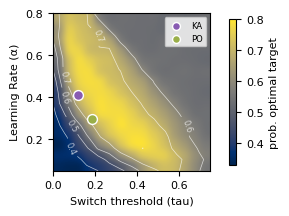

In [10]:
alpha_range_forage, V0_range_forage, res_grid_foraging = grid_search_foraging(env)
fig, ax = plot_parameter_grid_foraging(alpha_range_forage, V0_range_forage, res_grid_foraging, parameter_summary_df)
fig.savefig(os.path.join(FIGS_PATH, 'fig2d_parameter_space_foraging.svg'), dpi=300, bbox_inches='tight', transparent=True)
plt.show()

In [11]:
# Export source data (Figure 2d)
from popy.source_data import export_source_data

# heatmap matrix: rows = learning rate alpha (y axis), columns = switch threshold tau (x axis)
heatmap = pd.DataFrame(res_grid_foraging, columns=[f'tau = {tau:.6g}' for tau in V0_range_forage])
heatmap.insert(0, 'Learning rate alpha', alpha_range_forage)
foraging_fits = parameter_summary_df[parameter_summary_df['model'] == 'Foraging'].set_index(['monkey', 'parameter'])
fitted_dots = pd.DataFrame({'Monkey': ['KA', 'PO'],
                            'Switch threshold tau (mean of bootstrap fits)': [foraging_fits.loc[(m, 'V0'), 'mean'] for m in ['KA', 'PO']],
                            'Learning rate alpha (mean of bootstrap fits)': [foraging_fits.loc[(m, 'alpha'), 'mean'] for m in ['KA', 'PO']],
                            'Number of bootstrap fits': [foraging_fits.loc[(m, 'alpha'), 'n'] for m in ['KA', 'PO']]})
export_source_data('Figure 2d', {'Heatmap: prob. optimal target (rows: learning rate alpha, columns: switch threshold tau)': heatmap,
                                 'Dots: fitted parameters': fitted_dots},
                   f'Probability of choosing the optimal (high-payoff) target of the foraging model on a {len(alpha_range_forage)} x {len(V0_range_forage)} '
                   'grid of learning rate alpha (y axis) and switch threshold tau (x axis), one simulated session of 10,000 trials per grid point '
                   '(drawn as a smoothed heatmap with contour lines every 0.1). Dots: mean of the foraging-model parameters fitted to 100 bootstrap '
                   'resamples (with replacement) of the sessions of monkeys KA and PO.')

Figure 2d: source data saved (15 rows, 2 rows)
